# Experiment 3 – Backpropagation from Scratch
**Course:** Foundations of Deep Learning  
**Name:** Acchute Kashyap  
**Reg. No:** CH.SC.U4CSE23003  
**Date:** 16th October 2026

**Objective:** Understand how gradients are propagated through a neural network.


## Cell 1 – Setup

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
pd.set_option("display.float_format", lambda v: f"{v:.6f}")

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))
print("Setup complete.")

Setup complete.


---
## Task 18 – Network: 2 input neurons, 2 hidden neurons, 1 output neuron (sigmoid activation, MSE loss)

**Architecture:** `x₁, x₂  →  h₁, h₂  →  ŷ`  (fully connected, no bias terms)

* Hidden layer: $z_h = x\,W_1,\quad h = \sigma(z_h)$
* Output layer: $z_o = h\,W_2,\quad \hat{y} = \sigma(z_o)$
* Loss: $E = \tfrac{1}{2}(y-\hat{y})^2$   (the factor ½ cancels the 2 produced by differentiation)

Convention used throughout: $x$ is a **row vector**, `W1[i][j]` is the weight from input $x_i$ to hidden neuron $h_j$, and `W2[j]` is the weight from $h_j$ to the output.

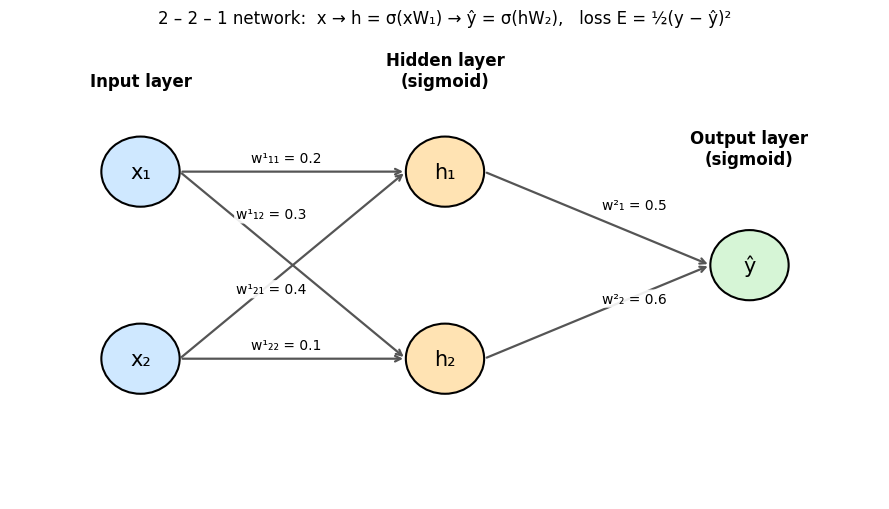

In [53]:
# ---------- Cell 2 : Task 18 – architecture diagram (edges labelled with the weights of Task 19) ----------
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.axis("off")

pos = {"x1": (1.5, 4.2), "x2": (1.5, 1.8), "h1": (5.0, 4.2), "h2": (5.0, 1.8), "o": (8.5, 3.0)}
labels = {"x1": "x₁", "x2": "x₂", "h1": "h₁", "h2": "h₂", "o": "ŷ"}
colors = {"x1": "#cfe8ff", "x2": "#cfe8ff", "h1": "#ffe3b3", "h2": "#ffe3b3", "o": "#d6f5d6"}

edges = [("x1","h1","w¹₁₁ = 0.2",0.35), ("x1","h2","w¹₁₂ = 0.3",0.30),
         ("x2","h1","w¹₂₁ = 0.4",0.30), ("x2","h2","w¹₂₂ = 0.1",0.35),
         ("h1","o","w²₁ = 0.5",0.5),    ("h2","o","w²₂ = 0.6",0.5)]
for a, b, txt, t in edges:
    (x0, y0), (x1_, y1) = pos[a], pos[b]
    ax.annotate("", xy=(x1_-0.45, y1), xytext=(x0+0.45, y0),
                arrowprops=dict(arrowstyle="->", lw=1.6, color="#555555"))
    ax.text(x0 + (x1_-x0)*t + 0.05, y0 + (y1-y0)*t + 0.12, txt, fontsize=10,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9))

for k, (px, py) in pos.items():
    ax.add_patch(plt.Circle((px, py), 0.45, fc=colors[k], ec="black", lw=1.5, zorder=3))
    ax.text(px, py, labels[k], ha="center", va="center", fontsize=15, zorder=4)

ax.text(1.5, 5.3, "Input layer", ha="center", fontsize=12, weight="bold")
ax.text(5.0, 5.3, "Hidden layer\n(sigmoid)", ha="center", fontsize=12, weight="bold")
ax.text(8.5, 4.3, "Output layer\n(sigmoid)", ha="center", fontsize=12, weight="bold")
ax.set_title("2 – 2 – 1 network:  x → h = σ(xW₁) → ŷ = σ(hW₂),   loss E = ½(y − ŷ)²", fontsize=12)
plt.tight_layout(); plt.show()

---
## Task 19 – Given parameters

$$W_1=\begin{bmatrix}0.2 & 0.3\\ 0.4 & 0.1\end{bmatrix},\qquad
W_2=\begin{bmatrix}0.5\\ 0.6\end{bmatrix},\qquad
x=\begin{bmatrix}1 & 0\end{bmatrix},\qquad y = 1$$

In [54]:
# ---------- Cell 3 : Task 19 – define the parameters ----------
W1 = np.array([[0.2, 0.3],
               [0.4, 0.1]])
W2 = np.array([[0.5],
               [0.6]])
x  = np.array([[1.0, 0.0]])      # row vector (1 x 2)
y  = 1.0

print("W1 (2x2) : rows = inputs, columns = hidden neurons")
display(pd.DataFrame(W1, index=["x1", "x2"], columns=["h1", "h2"]))
print("W2 (2x1) : rows = hidden neurons, column = output")
display(pd.DataFrame(W2, index=["h1", "h2"], columns=["ŷ"]))
print("Input  x =", x.ravel(), "   shape", x.shape)
print("Target y =", y)

W1 (2x2) : rows = inputs, columns = hidden neurons


,h1,h2
x1,0.200000,0.300000
x2,0.400000,0.100000


W2 (2x1) : rows = hidden neurons, column = output


,ŷ
h1,0.500000
h2,0.600000


Input  x = [1. 0.]    shape (1, 2)
Target y = 1.0


---
## Task 20 – Forward propagation

**Step 1 – hidden pre-activation**

$$z_h = xW_1 = \begin{bmatrix}1&0\end{bmatrix}\begin{bmatrix}0.2&0.3\\0.4&0.1\end{bmatrix}
= \begin{bmatrix}1(0.2)+0(0.4) & 1(0.3)+0(0.1)\end{bmatrix}=\begin{bmatrix}0.2 & 0.3\end{bmatrix}$$

**Step 2 – hidden activation:** $h_1=\sigma(0.2)=0.5498,\quad h_2=\sigma(0.3)=0.5744$

**Step 3 – output pre-activation**

$$z_o = hW_2 = 0.5498(0.5)+0.5744(0.6)=0.2749+0.3447=0.6196$$

**Step 4 – output:** $\hat{y}=\sigma(0.6196)=0.6501$

In [55]:
# ---------- Cell 4 : Task 20 – forward propagation, one scalar operation at a time ----------
# Step 1: hidden pre-activations (dot product written out by hand)
z_h1 = x[0,0]*W1[0,0] + x[0,1]*W1[1,0]
z_h2 = x[0,0]*W1[0,1] + x[0,1]*W1[1,1]
print(f"Step 1  z_h1 = {x[0,0]}*{W1[0,0]} + {x[0,1]}*{W1[1,0]} = {z_h1:.4f}")
print(f"        z_h2 = {x[0,0]}*{W1[0,1]} + {x[0,1]}*{W1[1,1]} = {z_h2:.4f}")

# Step 2: hidden activations
h1 = 1 / (1 + np.exp(-z_h1))
h2 = 1 / (1 + np.exp(-z_h2))
print(f"\nStep 2  h1 = sigmoid({z_h1:.1f}) = {h1:.4f}")
print(f"        h2 = sigmoid({z_h2:.1f}) = {h2:.4f}")

# Step 3: output pre-activation
z_o = h1*W2[0,0] + h2*W2[1,0]
print(f"\nStep 3  z_o = {h1:.4f}*{W2[0,0]} + {h2:.4f}*{W2[1,0]} = {z_o:.4f}")

# Step 4: network output
y_hat = 1 / (1 + np.exp(-z_o))
print(f"\nStep 4  y_hat = sigmoid({z_o:.4f}) = {y_hat:.4f}")

Step 1  z_h1 = 1.0*0.2 + 0.0*0.4 = 0.2000
        z_h2 = 1.0*0.3 + 0.0*0.1 = 0.3000

Step 2  h1 = sigmoid(0.2) = 0.5498
        h2 = sigmoid(0.3) = 0.5744

Step 3  z_o = 0.5498*0.5 + 0.5744*0.6 = 0.6196

Step 4  y_hat = sigmoid(0.6196) = 0.6501


---
## Task 21 – Hidden-layer activations and output prediction
The same forward pass written with matrices (this is the version reused for backpropagation).

In [56]:
# ---------- Cell 5 : Task 21 – vectorised forward pass + summary table ----------
def forward(x, W1, W2):
    z_h = x @ W1            # (1x2)
    h   = sigmoid(z_h)      # (1x2)
    z_o = h @ W2            # (1x1)
    y_hat = sigmoid(z_o)    # (1x1)
    return z_h, h, z_o, y_hat

z_h, h, z_o, y_hat = forward(x, W1, W2)

summary = pd.DataFrame({
    "Quantity": ["z_h1", "z_h2", "h1 = σ(z_h1)", "h2 = σ(z_h2)", "z_o", "ŷ = σ(z_o)"],
    "Value": [z_h[0,0], z_h[0,1], h[0,0], h[0,1], z_o[0,0], y_hat[0,0]],
}).set_index("Quantity")
display(summary)

print("Hidden-layer activations h =", h.ravel().round(4))
print("Output prediction     ŷ  =", round(float(y_hat[0,0]), 4))
print("Matches the scalar calculation of Cell 4:", np.allclose([h1, h2, y_hat[0,0]], [h[0,0], h[0,1], y_hat[0,0]]))

,Value
Quantity,
z_h1,0.200000
z_h2,0.300000
h1 = σ(z_h1),0.549834
h2 = σ(z_h2),0.574443
z_o,0.619583
ŷ = σ(z_o),0.650124


Hidden-layer activations h = [0.5498 0.5744]
Output prediction     ŷ  = 0.6501
Matches the scalar calculation of Cell 4: True


---
## Task 22 – Loss

$$E=\tfrac12\,(y-\hat y)^2=\tfrac12\,(1-0.6501)^2=\tfrac12\,(0.3499)^2=\tfrac12\,(0.1224)=0.0612$$

In [57]:
# ---------- Cell 6 : Task 22 – loss ----------
error = y - y_hat[0,0]
E = 0.5 * error ** 2
print(f"y - y_hat      = {y} - {y_hat[0,0]:.4f} = {error:.4f}")
print(f"(y - y_hat)^2  = {error**2:.4f}")
print(f"E = 1/2 * {error**2:.4f} = {E:.4f}   (full precision: {E:.8f})")

y - y_hat      = 1.0 - 0.6501 = 0.3499
(y - y_hat)^2  = 0.1224
E = 1/2 * 0.1224 = 0.0612   (full precision: 0.06120675)


---
## Task 23 – Gradients by backpropagation (chain rule)

Goal: find $\dfrac{\partial E}{\partial W_2}$ and $\dfrac{\partial E}{\partial W_1}$ by working **backwards** from the loss.

Forward chain: $\;W_1 \to z_h \to h \to z_o \to \hat y \to E$

### Step 1 – output error signal $\delta_o$
$$\frac{\partial E}{\partial \hat y} = \hat y - y = 0.6501-1=-0.3499$$
$$\frac{\partial \hat y}{\partial z_o}=\hat y(1-\hat y)=0.6501(0.3499)=0.2275$$
$$\boxed{\delta_o=\frac{\partial E}{\partial z_o}=\frac{\partial E}{\partial \hat y}\cdot\frac{\partial \hat y}{\partial z_o}=(-0.3499)(0.2275)=-0.0796}$$

### Step 2 – gradient for $W_2$  (since $z_o=h_1w^{(2)}_1+h_2w^{(2)}_2$, we have $\partial z_o/\partial w^{(2)}_j=h_j$)
$$\frac{\partial E}{\partial w^{(2)}_1}=\delta_o\,h_1=(-0.0796)(0.5498)=-0.0438$$
$$\frac{\partial E}{\partial w^{(2)}_2}=\delta_o\,h_2=(-0.0796)(0.5744)=-0.0457$$

### Step 3 – push the error back to the hidden layer
$$\frac{\partial E}{\partial h_j}=\delta_o\,w^{(2)}_j:\qquad \frac{\partial E}{\partial h_1}=(-0.0796)(0.5)=-0.0398,\quad \frac{\partial E}{\partial h_2}=(-0.0796)(0.6)=-0.0478$$
$$\sigma'(z_{h_j})=h_j(1-h_j):\qquad h_1(1-h_1)=0.2475,\quad h_2(1-h_2)=0.2445$$
$$\boxed{\delta_{h_1}=(-0.0398)(0.2475)=-0.00985,\qquad \delta_{h_2}=(-0.0478)(0.2445)=-0.01167}$$

### Step 4 – gradient for $W_1$  (since $z_{h_j}=\sum_i x_i w^{(1)}_{ij}$, we have $\partial z_{h_j}/\partial w^{(1)}_{ij}=x_i$)
$$\frac{\partial E}{\partial w^{(1)}_{ij}}=x_i\,\delta_{h_j}\;\;\Rightarrow\;\;
\frac{\partial E}{\partial W_1}=x^{T}\delta_h=\begin{bmatrix}1\\0\end{bmatrix}\begin{bmatrix}-0.00985&-0.01167\end{bmatrix}=\begin{bmatrix}-0.00985&-0.01167\\0&0\end{bmatrix}$$

The second row is **zero because $x_2=0$**: an input that is switched off cannot influence the loss, so its weights receive no gradient.

In [58]:
# ---------- Cell 7 : Task 23 – backpropagation, one chain-rule link at a time ----------
# Step 1 : output error signal
dE_dyhat  = y_hat - y                       # dE/d(y_hat)
dyhat_dzo = y_hat * (1 - y_hat)             # sigmoid derivative at the output
delta_o   = dE_dyhat * dyhat_dzo            # dE/d(z_o)
print("STEP 1  output layer")
print(f"  dE/dy_hat   = y_hat - y       = {dE_dyhat[0,0]:.4f}")
print(f"  dy_hat/dz_o = y_hat(1-y_hat)  = {dyhat_dzo[0,0]:.4f}")
print(f"  delta_o     = product         = {delta_o[0,0]:.4f}")

# Step 2 : gradient of W2
dE_dW2 = h.T @ delta_o                      # (2x1)
print("\nSTEP 2  gradient for W2   (delta_o * h_j)")
print(f"  dE/dw2_1 = {delta_o[0,0]:.4f} * {h[0,0]:.4f} = {dE_dW2[0,0]:.4f}")
print(f"  dE/dw2_2 = {delta_o[0,0]:.4f} * {h[0,1]:.4f} = {dE_dW2[1,0]:.4f}")

# Step 3 : error signal at the hidden layer
dE_dh   = delta_o @ W2.T                    # (1x2)  error sent back through W2
dh_dzh  = h * (1 - h)                       # sigmoid derivative at hidden layer
delta_h = dE_dh * dh_dzh                    # dE/d(z_h)
print("\nSTEP 3  hidden layer error signal")
print("  dE/dh        =", dE_dh.ravel().round(4))
print("  h(1-h)       =", dh_dzh.ravel().round(4))
print("  delta_h      =", delta_h.ravel().round(5))

# Step 4 : gradient of W1
dE_dW1 = x.T @ delta_h                      # (2x2)
print("\nSTEP 4  gradient for W1   (x_i * delta_h_j)")
display(pd.DataFrame(dE_dW1, index=["x1", "x2"], columns=["to h1", "to h2"]))
print("Row for x2 is zero because x2 = 0 (that input contributes nothing to the loss).")

STEP 1  output layer
  dE/dy_hat   = y_hat - y       = -0.3499
  dy_hat/dz_o = y_hat(1-y_hat)  = 0.2275
  delta_o     = product         = -0.0796

STEP 2  gradient for W2   (delta_o * h_j)
  dE/dw2_1 = -0.0796 * 0.5498 = -0.0438
  dE/dw2_2 = -0.0796 * 0.5744 = -0.0457

STEP 3  hidden layer error signal
  dE/dh        = [-0.0398 -0.0478]
  h(1-h)       = [0.2475 0.2445]
  delta_h      = [-0.00985 -0.01167]

STEP 4  gradient for W1   (x_i * delta_h_j)


,to h1,to h2
x1,-0.009849,-0.011673
x2,0.000000,0.000000


Row for x2 is zero because x2 = 0 (that input contributes nothing to the loss).


---
## Task 24 – Weight update with gradient descent

$$W_{new}=W_{old}-\eta\,\frac{\partial E}{\partial W}$$

The task does not specify a learning rate, so **η = 0.5** is used here (Cell 9 shows what other values would give).

$$W_2^{new}=\begin{bmatrix}0.5\\0.6\end{bmatrix}-0.5\begin{bmatrix}-0.04376\\-0.04572\end{bmatrix}=\begin{bmatrix}0.52188\\0.62286\end{bmatrix}$$

$$W_1^{new}=\begin{bmatrix}0.2&0.3\\0.4&0.1\end{bmatrix}-0.5\begin{bmatrix}-0.00985&-0.01167\\0&0\end{bmatrix}=\begin{bmatrix}0.20492&0.30584\\0.4&0.1\end{bmatrix}$$

In [59]:
# ---------- Cell 8 : Task 24 – gradient-descent update with eta = 0.5 ----------
eta = 0.5

W2_new = W2 - eta * dE_dW2
W1_new = W1 - eta * dE_dW1

print(f"Learning rate eta = {eta}\n")
print("W2 :  old  ->  new   (change = -eta * gradient)")
display(pd.DataFrame({"old": W2.ravel(), "gradient": dE_dW2.ravel(), "new": W2_new.ravel()},
                     index=["w2_1 (h1→ŷ)", "w2_2 (h2→ŷ)"]))
print("W1 :  old  ->  new")
display(pd.DataFrame({"old": W1.ravel(), "gradient": dE_dW1.ravel(), "new": W1_new.ravel()},
                     index=["w1_11 (x1→h1)", "w1_12 (x1→h2)", "w1_21 (x2→h1)", "w1_22 (x2→h2)"]))

# Did the update help?  Run the forward pass again with the new weights.
_, _, _, y_hat_new = forward(x, W1_new, W2_new)
E_new = 0.5 * (y - y_hat_new[0,0]) ** 2
print(f"Before update :  y_hat = {y_hat[0,0]:.4f},  E = {E:.4f}")
print(f"After  update :  y_hat = {y_hat_new[0,0]:.4f},  E = {E_new:.4f}   -> loss decreased: {E_new < E}")

Learning rate eta = 0.5

W2 :  old  ->  new   (change = -eta * gradient)


,old,gradient,new
w2_1 (h1→ŷ),0.500000,-0.043758,0.521879
w2_2 (h2→ŷ),0.600000,-0.045716,0.622858


W1 :  old  ->  new


,old,gradient,new
w1_11 (x1→h1),0.200000,-0.009849,0.204925
w1_12 (x1→h2),0.300000,-0.011673,0.305836
w1_21 (x2→h1),0.400000,0.000000,0.400000
w1_22 (x2→h2),0.100000,0.000000,0.100000


Before update :  y_hat = 0.6501,  E = 0.0612
After  update :  y_hat = 0.6562,  E = 0.0591   -> loss decreased: True


In [60]:
# ---------- Cell 9 : Task 24 (extra) – effect of the learning rate on a single update ----------
rows = []
for lr in [0.01, 0.1, 0.5, 1.0, 2.0]:
    W1n, W2n = W1 - lr * dE_dW1, W2 - lr * dE_dW2
    yn = forward(x, W1n, W2n)[3][0,0]
    rows.append({"η": lr, "ŷ after one step": yn, "Loss after one step": 0.5 * (y - yn) ** 2,
                 "Loss reduction": E - 0.5 * (y - yn) ** 2})
display(pd.DataFrame(rows).set_index("η"))
print(f"Loss before the update: {E:.6f}.  Larger η moves further down the slope in one step.")

,ŷ after one step,Loss after one step,Loss reduction
η,,,
0.010000,0.650245,0.061164,0.000042
0.100000,0.651334,0.060784,0.000423
0.500000,0.656169,0.059110,0.002097
1.000000,0.662190,0.057058,0.004149
2.000000,0.674152,0.053088,0.008118


Loss before the update: 0.061207.  Larger η moves further down the slope in one step.


---
## Task 25 – Verify the results using Python

Four independent checks are used:

1. **Hand-calculated values** (the 4-decimal numbers derived above) against the code.
2. **Numerical gradient check** – perturb every weight by ±ε and measure how the loss changes (finite differences). This does not use backpropagation at all.
3. **PyTorch autograd** – an automatic-differentiation library computes the same gradients.
4. **Training loop** – repeating forward → backward → update should keep reducing the loss.

In [61]:
# ---------- Cell 10 : Task 25 (a) – complete forward + backward pass and comparison with the hand results ----------
def backprop(x, y, W1, W2):
    z_h, h, z_o, y_hat = forward(x, W1, W2)
    E = 0.5 * np.sum((y - y_hat) ** 2)
    delta_o = (y_hat - y) * y_hat * (1 - y_hat)
    gW2 = h.T @ delta_o
    delta_h = (delta_o @ W2.T) * h * (1 - h)
    gW1 = x.T @ delta_h
    return E, y_hat, h, gW1, gW2

E_code, y_hat_code, h_code, gW1, gW2 = backprop(x, y, W1, W2)

# values obtained by hand in Tasks 20-24 (rounded to 4-5 decimals)
hand = {
    "h1":        (0.5498,   h_code[0,0]),
    "h2":        (0.5744,   h_code[0,1]),
    "ŷ":         (0.6501,   y_hat_code[0,0]),
    "Loss E":    (0.0612,   E_code),
    "dE/dw2_1":  (-0.0438,  gW2[0,0]),
    "dE/dw2_2":  (-0.0457,  gW2[1,0]),
    "dE/dw1_11": (-0.00985, gW1[0,0]),
    "dE/dw1_12": (-0.01167, gW1[0,1]),
    "dE/dw1_21": (0.0,      gW1[1,0]),
    "dE/dw1_22": (0.0,      gW1[1,1]),
}
check = pd.DataFrame([{"Quantity": k, "Hand value": a, "Python value": b, "|difference|": abs(a-b),
                       "Match": "✔" if abs(a-b) < 6e-5 else "✘"} for k, (a, b) in hand.items()]).set_index("Quantity")
display(check)
print("All hand-calculated values agree with Python:", (check["Match"] == "✔").all())

,Hand value,Python value,|difference|,Match
Quantity,,,,
h1,0.549800,0.549834,0.000034,✔
h2,0.574400,0.574443,0.000043,✔
ŷ,0.650100,0.650124,0.000024,✔
Loss E,0.061200,0.061207,0.000007,✔
dE/dw2_1,-0.043800,-0.043758,0.000042,✔
dE/dw2_2,-0.045700,-0.045716,0.000016,✔
dE/dw1_11,-0.009850,-0.009849,0.000001,✔
dE/dw1_12,-0.011670,-0.011673,0.000003,✔
dE/dw1_21,0.000000,0.000000,0.000000,✔


All hand-calculated values agree with Python: True


In [62]:
# ---------- Cell 11 : Task 25 (b) – numerical gradient check (finite differences) ----------
def loss_only(W1_, W2_):
    return backprop(x, y, W1_, W2_)[0]

eps = 1e-6
num_gW1 = np.zeros_like(W1)
num_gW2 = np.zeros_like(W2)
for i in range(W1.shape[0]):
    for j in range(W1.shape[1]):
        Wp, Wm = W1.copy(), W1.copy()
        Wp[i, j] += eps; Wm[i, j] -= eps
        num_gW1[i, j] = (loss_only(Wp, W2) - loss_only(Wm, W2)) / (2 * eps)
for i in range(W2.shape[0]):
    Wp, Wm = W2.copy(), W2.copy()
    Wp[i, 0] += eps; Wm[i, 0] -= eps
    num_gW2[i, 0] = (loss_only(W1, Wp) - loss_only(W1, Wm)) / (2 * eps)

print("Backprop  dE/dW1:\n", gW1)
print("Numerical dE/dW1:\n", num_gW1)
print("\nBackprop  dE/dW2:\n", gW2.ravel())
print("Numerical dE/dW2:\n", num_gW2.ravel())
max_diff = max(np.abs(gW1 - num_gW1).max(), np.abs(gW2 - num_gW2).max())
print(f"\nLargest difference between backprop and numerical gradients: {max_diff:.2e}")
print("Gradient check passed:", max_diff < 1e-8)

Backprop  dE/dW1:
 [[-0.009849 -0.011673]
 [ 0.        0.      ]]
Numerical dE/dW1:
 [[-0.009849 -0.011673]
 [ 0.        0.      ]]

Backprop  dE/dW2:
 [-0.043758 -0.045716]
Numerical dE/dW2:
 [-0.043758 -0.045716]

Largest difference between backprop and numerical gradients: 1.11e-11
Gradient check passed: True


In [63]:
# ---------- Cell 12 : Task 25 (c) – PyTorch automatic differentiation ----------
try:
    import torch

    # Use Python lists to avoid PyTorch's NumPy bridge
    tW1 = torch.tensor(W1.tolist(), requires_grad=True)
    tW2 = torch.tensor(W2.tolist(), requires_grad=True)
    tx = torch.tensor(x.tolist())
    ty = torch.tensor([[y]])

    t_yhat = torch.sigmoid(torch.sigmoid(tx @ tW1) @ tW2)
    t_loss = 0.5 * ((ty - t_yhat) ** 2).sum()
    t_loss.backward()

    torch_gW1 = np.asarray(tW1.grad.detach().cpu().tolist())
    torch_gW2 = np.asarray(tW2.grad.detach().cpu().tolist())

    print("PyTorch loss      :", round(t_loss.item(), 8))
    print("PyTorch dE/dW2    :", torch_gW2.ravel())
    print("PyTorch dE/dW1    :\n", torch_gW1)
    print("\nMatches our backprop (W1):", np.allclose(torch_gW1, gW1))
    print("Matches our backprop (W2):", np.allclose(torch_gW2, gW2))

except ImportError:
    print("PyTorch is not installed in this environment - skipping this check (Cells 10 and 11 already verify the results).")
except RuntimeError as exc:
    print("PyTorch check skipped:", exc)

PyTorch loss      : 0.06120677
PyTorch dE/dW2    : [-0.043758 -0.045716]
PyTorch dE/dW1    :
 [[-0.009849 -0.011673]
 [-0.       -0.      ]]

Matches our backprop (W1): True
Matches our backprop (W2): True


,loss,y_hat
step,,
0,0.061207,0.650124
1,0.059110,0.656169
2,0.057100,0.662065
5,0.051557,0.678885
10,0.043750,0.704195
50,0.015634,0.823174
100,0.007157,0.880356
200,0.002995,0.922602


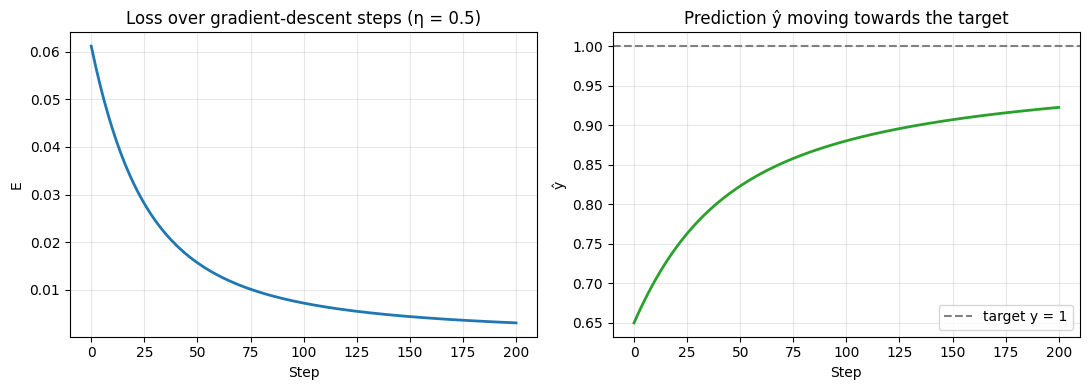

In [64]:
# ---------- Cell 13 : Task 25 (d) – repeat forward -> backward -> update and watch the loss fall ----------
W1_t, W2_t = W1.copy(), W2.copy()
history = []
for step in range(201):
    E_t, y_t, _, g1, g2 = backprop(x, y, W1_t, W2_t)
    history.append((step, E_t, y_t[0,0]))
    W1_t -= eta * g1
    W2_t -= eta * g2

hist = pd.DataFrame(history, columns=["step", "loss", "y_hat"]).set_index("step")
display(hist.loc[[0, 1, 2, 5, 10, 50, 100, 200]])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(hist.index, hist["loss"], linewidth=2)
axes[0].set_title(f"Loss over gradient-descent steps (η = {eta})"); axes[0].set_xlabel("Step"); axes[0].set_ylabel("E"); axes[0].grid(alpha=0.3)
axes[1].plot(hist.index, hist["y_hat"], linewidth=2, color="tab:green"); axes[1].axhline(y, linestyle="--", color="gray", label="target y = 1")
axes[1].set_title("Prediction ŷ moving towards the target"); axes[1].set_xlabel("Step"); axes[1].set_ylabel("ŷ"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()